# Классификация звёзд и галактик по фотометрическим данным

# Разведочный анализ данных

### **Цель:** Исследовать фотометрические признаки SDSS-каталога, оценить разделимость классов STAR/GALAXY/QSO по цветам и яркостям, выявить проблемы качества данных и определить допустимый набор признаков для обучения модели.


### **Задача:** По фотометрическим данным  Sloan Digital Sky Survey (яркости в 5 фильтрах u, g, r, i, z, координаты RA, DEC, параметры формы и т.д.) определить тип объекта: STAR, GALAXY (и, возможно, QSO, если встретится).

https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17 ссылка на датасет

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

raw_df = pd.read_csv("star_classification.csv", dtype={
        "obj_ID": "string",
        "spec_obj_ID": "string"
    })

display(raw_df.head())

raw_df.info()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1237660961327743232,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6543777369295181824,GALAXY,0.634794,5812,56354,171
1,1237664879951151360,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,11760142036707334144,GALAXY,0.779136,10445,58158,427
2,1237660961330430208,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5152200256025548800,GALAXY,0.644195,4576,55592,299
3,1237663478724297984,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,10301071412954421248,GALAXY,0.932346,9149,58039,775
4,1237680272041378048,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6891864880783316992,GALAXY,0.116123,6121,56187,842


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  string 
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  string 
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(8), int64(7), 

In [2]:
print(raw_df.shape)
raw_df.count()

(100000, 18)


obj_ID         100000
alpha          100000
delta          100000
u              100000
g              100000
r              100000
i              100000
z              100000
run_ID         100000
rerun_ID       100000
cam_col        100000
field_ID       100000
spec_obj_ID    100000
class          100000
redshift       100000
plate          100000
MJD            100000
fiber_ID       100000
dtype: int64

## Таблица названий колонок

| Название столбца | Название признака | Единицы измерения | Значение | 
|---|---|---|---|
| obj_ID | Идентификатор фотометрического объекта |  |  |
| alpha | Прямое восхождение, RA | градусы | Небесная долгота |
| delta | Склонение, Dec | градусы | Небесная широта |
| u | ultraviolet / фиолетово-синий | магнитуда | Яркость объекта |
| g | green / зелёный | магнитуда | Яркость объекта |
| r | red / красный | магнитуда | Яркость объекта |
| i | near infrared / ближний ИК | магнитуда | Яркость объекта |
| z | farther near infrared | магнитуда | Яркость объекта |
| run_ID | Идентификатор съёмочного прогона |  | Обычно соответствует ночи наблюдений или определённому запуску телескопа. Не является физическим признаком объекта. |
| rerun_ID | Версия повторной обработки данных |  | Служебная информация. |
| cam_col | Номер колонки камеры |  | У SDSS была большая камера, состоящая из нескольких CCD-колонок. cam_col показывает, в какой части детектора был зарегистрирован объект. |
| field_ID | Идентификатор поля наблюдения |  | Поле — это участок неба, снятый за одну экспозицию/в рамках определённой программы. |
| spec_obj_ID | Идентификатор спектроскопического объекта |  | Он связывает фотометрический объект со спектром, по которому, вероятно, получили: class, redshift. |
| class | Классы объектов | (QSO, STAR, GALAXY) | Звезда — это самосветящийся газовый шар, в котором идут термоядерные реакции. Галактика — это большая система из звёзд, газа, пыли, тёмной материи и часто активного ядра. Квазар — это очень яркое активное галактическое ядро, питаемое сверхмассивной чёрной дырой. |
| redshift | Красное смещение |  | Красное смещение показывает, насколько длина волны света растянулась между моментом излучения и моментом наблюдения. |
| plate | Спектроскопическая пластина |  | В SDSS для спектроскопии делали пластину с отверстиями под волокна, куда направляли свет от выбранных объектов. |
| MJD | Модифицированная юлианская дата |  | Способ записи даты в астрономии. Это позволяет удобно хранить дату наблюдения как число. |
| fiber_ID | Номер волокна на спектроскопической пластине |  | Каждый объект направлялся в определённое оптическое волокно. |

## Таблица использования данных

| Название столбца | Тип | Роль | Использовать в модели? | Комментарий |
|---|---|---|---|---|
| obj_ID | float64 | идентификатор | нет | контроль уникальности, читать как строку |
| alpha | float64 | RA | возможно | координата на небе |
| delta | float64 | Dec | возможно | координата на небе |
| u | float64 | магнитуда | да | фотометрия |
| g | float64 | магнитуда | да | фотометрия |
| r | float64 | магнитуда | да | фотометрия |
| i | float64 | магнитуда | да | фотометрия |
| z | float64 | магнитуда | да | фотометрия |
| run_ID | int64 | служебная информация | нет |  |
| rerun_ID | int64 | служебная информация | нет |  |
| cam_col | int64 | служебная информация | нет |  |
| field_ID | int64 | служебная информация | нет |  |
| spec_obj_ID | float64 | служебная информация | нет | критично для контроля утечек, читать как строку |
| class | object  | цель | да |  |
| redshift | float64 | аккуратно | спектроскопическая информация, риск утечки |
| plate | int64 | служебная информация | нет |  |
| MJD | int64 | дата | нет |  |
| fiber_ID | int64 | служебная информация | нет |  |

## Ещё немного теории

Фильтр - это оптический канал, который пропускает свет только в определённом диапазоне длин волн.

- u - ультрафиолетовый / фиолетово-синий
- g - зелёный
- r - красный
- i - ближний инфракрасный
- z - ещё более красный / ближний инфракрасный

В астрономии яркость часто измеряют не в привычных физических единицах, а в звёздных величинах, или магнитудах. Чем меньше магнитуда, тем ярче объект.
Причина в том, что шкала логарифмическая. Человеческий глаз и многие астрономические процессы воспринимают яркость не линейно, а примерно логарифмически.

Самые важные признаки в этой задаче - не сами магнитуды, а их разности:
- u - g
- g - r
- r - i
- i - z

Это называют цветовыми индексами или просто цветами.

Почему цвета важнее абсолютных яркостей?
Потому что абсолютная магнитуда зависит от многих факторов:
- насколько объект яркий сам по себе;
- как далеко он находится;
- сколько пыли поглощает свет;
- какие условия наблюдения.
А цвет - это отношение яркостей в двух фильтрах. Он частично убирает влияние расстояния и общей яркости и лучше показывает природу объекта.

Звезда - это самосветящийся газовый объект, в котором идут термоядерные реакции.
Для телескопа звезда выглядит почти как точка. Её изображение размывается атмосферой и оптикой, но физически это точечный источник.

Звёзды имеют довольно упорядоченные спектры. Грубо, звезда похожа на объект с определённой температурой:
- горячие звёзды излучают больше в синем/ультрафиолетовом диапазоне;
- холодные звёзды излучают больше в красном/инфракрасном.
Поэтому звёзды на "цвет - цвет" диаграммах часто образуют узкую последовательность.

Галактика - это большая система из звёзд, газа, пыли и тёмной материи.
Галактика - это не один простой объект. Это смесь:
- молодых горячих звёзд;
- старых холодных звёзд;
- газа;
- пыли;
- областей звездообразования;
- возможно, активного ядра.
Поэтому цвета галактик более разбросаны.
На "цвет - цвет" диаграммах галактики обычно занимают более широкую область, чем звёзды.

Квазар - это очень яркое активное ядро далёкой галактики. В центре такой галактики находится сверхмассивная чёрная дыра, и вещество, падающее на неё, разогревается и ярко светится.
Квазары можно наблюдать на огромных расстояниях. Сложность в том, что квазар по изображению может быть похож на звезду: он тоже выглядит почти точечным источником. Но физически это совсем другой объект.
По фотометрии квазары могут напоминать:
- звёзды;
- галактики;
- объекты с необычными цветами.
Поэтому класс QSO обычно самый сложный для классификации.

redshift - это красное смещение.
Оно показывает, насколько длина волны света растянулась между моментом излучения и моментом наблюдения. То есть:
- если объект удаляется или находится в расширяющейся Вселенной, его свет смещается в красную сторону;
- чем больше красное смещение, тем обычно дальше объект и тем раньше мы видим его свет.

Для проекта redshift очень важен, но не как признак модели, а как источник риска утечки.
redshift обычно получают не из простой фотометрии, а из спектроскопии. То есть это более глубокая информация, чем u, g, r, i, z.

Если дать модели redshift, она может научиться почти правилу:
- почти ноль - звезда
- среднее значение - галактика
- большое значение - квазар

Задача решается потому, что разные типы объектов по-разному распределяют свет по фильтрам.
Звёзды имеют более упорядоченные цвета.
Галактики имеют более сложные и разбросанные цвета.
Квазары могут быть похожи на звёзды по форме, но отличаться по спектральным особенностям и красному смещению. Поэтому в пространстве цветов классы частично разделяются.

Формальная постановка задачи.

Дано:
X — матрица объектов
y — целевая переменная

Каждый объект описывается 
- фотометрическими признаками: 
    - x = (u, g, r, i, z)
- производными цветовыми признаками: 
    - $c_{ug}$ =  u - g 
    - $c_{gr}$ =  g - r 
    - $c_{ri}$ =  r - i 
    - $c_{iz}$ =  i - z 

Задача восстановить отоборажение: 
- f: X -> Y, где Y = {STAR, GALAXY, QSO}

Магнетуды: 
- m = $-2.5log_{10}(F/F_{0})$, где F - поток излучения, m - магнитуда, $F_{0}$ - нулевой поток калибровочной системы.

Поток излучения (его также называют лучистым потоком или мощностью излучения) - это физическая величина, которая показывает, сколько энергии переносится электромагнитным излучением (например, светом) через какую-либо поверхность в единицу времени.

## 1. Исследуем выбросы и невалидные значения

In [3]:
print("Количество пропусков класса: ", raw_df["class"].isna().sum())
print("Уникальные значения класса: ", raw_df['class'].unique())
print("Количество дубликатов строк: ", raw_df.duplicated().sum())
print("Количество дубликатов идентификаторов фотометрического объекта: ", raw_df["obj_ID"].duplicated().sum())
print("Количество дубликатов идентификаторов спектроскопического объекта: ", raw_df["spec_obj_ID"].duplicated().sum())

Количество пропусков класса:  0
Уникальные значения класса:  ['GALAXY' 'QSO' 'STAR']
Количество дубликатов строк:  0
Количество дубликатов идентификаторов фотометрического объекта:  19154
Количество дубликатов идентификаторов спектроскопического объекта:  0


In [4]:
same_obj_id = raw_df.groupby("obj_ID")["class"].nunique().loc[lambda x: x > 1]
print(len(same_obj_id))

4938


In [5]:
conflict_obj_id = raw_df.groupby("obj_ID")["class"].nunique(dropna=True).loc[lambda x: x > 1].index

conflict_mask = raw_df["obj_ID"].isin(conflict_obj_id)

print("Проблемных obj_ID:", len(conflict_obj_id))
print("Затронутых строк:", conflict_mask.sum())
print("Доля строк:", conflict_mask.mean())

Проблемных obj_ID: 4938
Затронутых строк: 12778
Доля строк: 0.12778


In [6]:
conflict_spec_ids = raw_df.groupby("spec_obj_ID")["class"].nunique().loc[lambda x: x > 1].index
print("Проблемных spec_obj_ID:", len(conflict_spec_ids))

Проблемных spec_obj_ID: 0


### Есть проблемы с конфликтующими "obj_ID", поэтому уберем конфликтующие строки, чтобы не препятствовать обучению модели. Можно и разобраться, что это за строки, но это уже результат долгого исследования

In [7]:
conflict_mask = raw_df["obj_ID"].isin(conflict_obj_id)
working_df = raw_df.loc[~conflict_mask].copy().reset_index(drop=True)

print("Было строк:", len(raw_df))
print("Удалено строк:", int(conflict_mask.sum()))
print("Осталось строк:", len(working_df))

Было строк: 100000
Удалено строк: 12778
Осталось строк: 87222


In [8]:
ranges_of_vals = {
    "alpha": (0, 360),
    "delta": (-90, 90),
    "u": (0, 40),
    "g": (0, 40),
    "r": (0, 40),
    "i": (0, 40),
    "z": (0, 40),
    "redshift": (-1, 10),
}

mask = pd.Series(False, index=working_df.index)

for col, (low, high) in ranges_of_vals.items():
    x = working_df[col]
    col_bad = x.isna() | (x < low) | (x > high)
    print(f"{col}: {col_bad.sum()} строк вне [{low}, {high}] или NaN")
    mask |= col_bad

df = working_df.loc[~mask].reset_index(drop=True)
print("\nБыло строк:", len(working_df))
print("Стало строк:", len(df))

alpha: 0 строк вне [0, 360] или NaN
delta: 0 строк вне [-90, 90] или NaN
u: 1 строк вне [0, 40] или NaN
g: 1 строк вне [0, 40] или NaN
r: 0 строк вне [0, 40] или NaN
i: 0 строк вне [0, 40] или NaN
z: 1 строк вне [0, 40] или NaN
redshift: 0 строк вне [-1, 10] или NaN

Было строк: 87222
Стало строк: 87221


## 2. Рассмотрим распределение объектов по классам

class
GALAXY    55005
STAR      17607
QSO       14609
Name: count, dtype: int64


C:\Users\andru\AppData\Local\Temp\ipykernel_17340\2502033940.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.bar(['GALAXY', 'STAR', 'QSO'], [class_diff[0], class_diff[1], class_diff[2]], color=['darkorange', 'lightgreen', 'darkblue'])


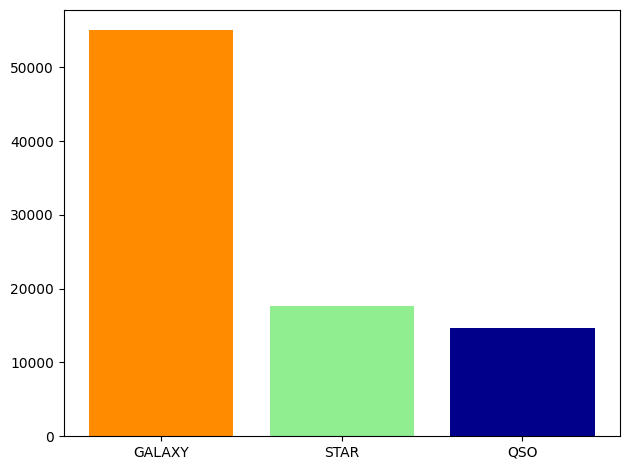

In [9]:
class_diff = df["class"].value_counts()
print(class_diff)

plt.bar(['GALAXY', 'STAR', 'QSO'], [class_diff[0], class_diff[1], class_diff[2]], color=['darkorange', 'lightgreen', 'darkblue'])

plt.tight_layout()
plt.show()

### Присутствует большое смещение в сторону галактик по данным. Достаточно мало звёзд и квазаров.

## 3. Рассмотрим графики распределения магнитуд

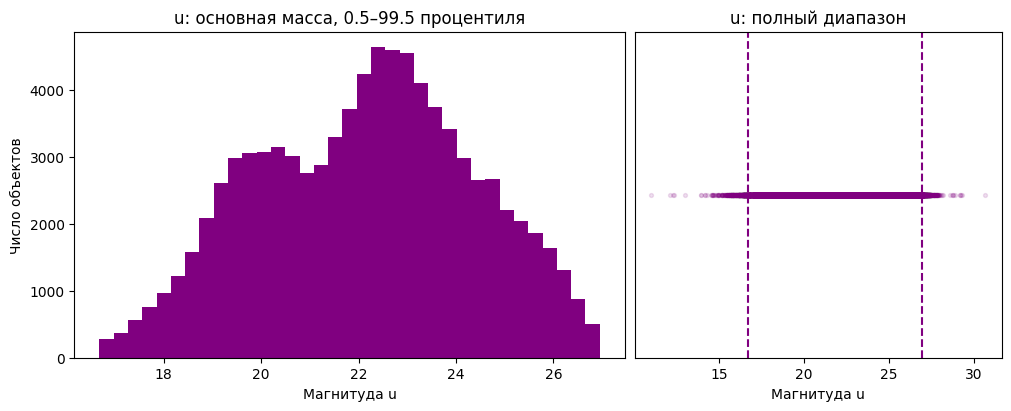

Магнитуда u: в основном окне 86347 объектов, за границами 874 объектов


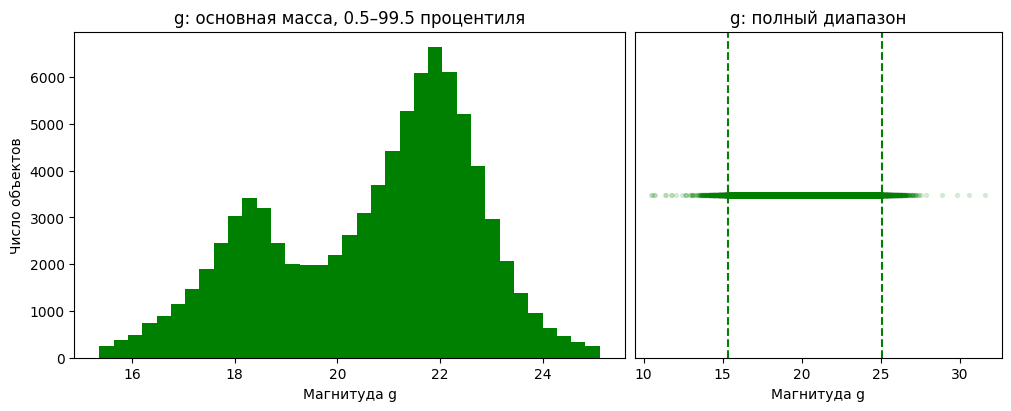

Магнитуда g: в основном окне 86347 объектов, за границами 874 объектов


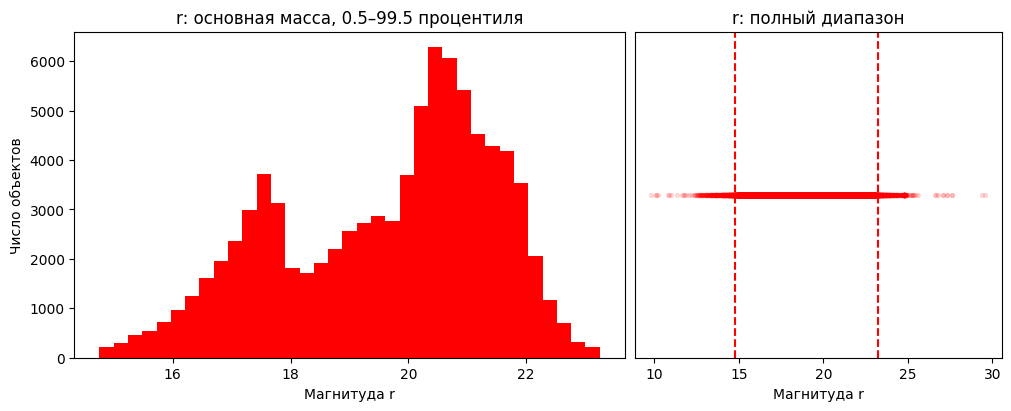

Магнитуда r: в основном окне 86347 объектов, за границами 874 объектов


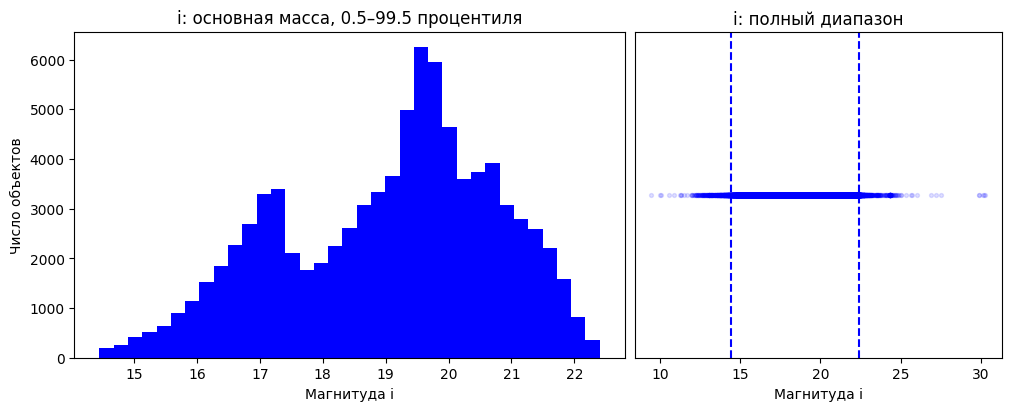

Магнитуда i: в основном окне 86347 объектов, за границами 874 объектов


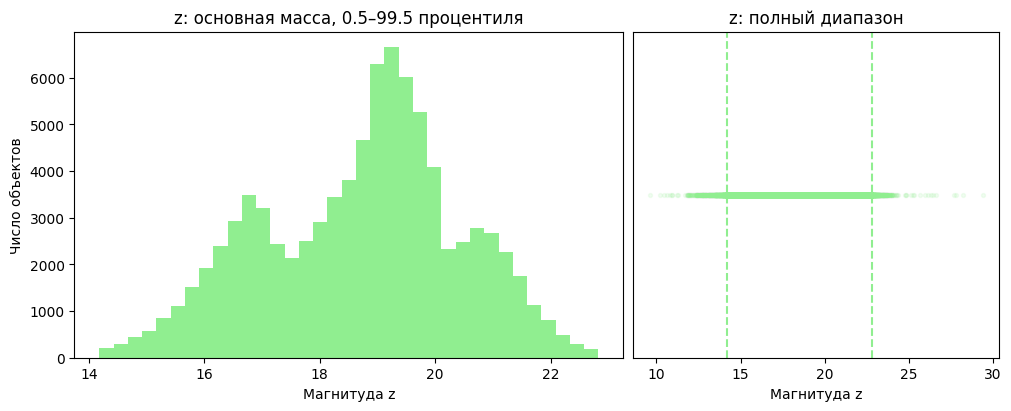

Магнитуда z: в основном окне 86347 объектов, за границами 874 объектов


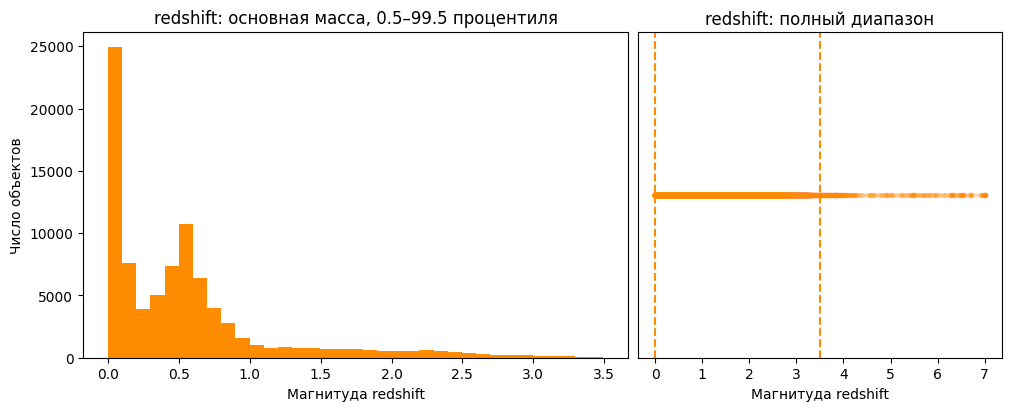

Магнитуда redshift: в основном окне 86347 объектов, за границами 874 объектов


In [10]:
mag_cols = ["u", "g", "r", "i", "z", "redshift"]
colors_magns=["purple", "green", "red", "blue", "lightgreen" ,"darkorange"]

for col, c in zip(mag_cols, colors_magns):
    values = df[col].dropna()
    preview_low, preview_high = values.quantile([0.005, 0.995])
    preview_central = values.between(preview_low, preview_high)
    
    fig, (ax_main, ax_full) = plt.subplots(
        1,
        2,
        figsize=(10, 4),
        width_ratios=[3, 2],
        constrained_layout=True,
    )

    ax_main.hist(values.loc[preview_central], bins=35, color=c)
    ax_main.set(
        xlabel=f"Магнитуда {col}",
        ylabel="Число объектов",
        title=f"{col}: основная масса, 0.5–99.5 процентиля",
    )
    ax_full.scatter(
        values,
        np.zeros(len(values)),
        s=8,
        alpha=0.12,
        color=c,
    )

    ax_full.axvline(preview_low, linestyle="--", color=c)
    ax_full.axvline(preview_high, linestyle="--", color=c)

    ax_full.set(
        xlabel=f"Магнитуда {col}",
        yticks=[],
        title=f"{col}: полный диапазон",
    )

    plt.show()

    print(
        f"Магнитуда {col}: "
        f"в основном окне {int(preview_central.sum())} объектов, "
        f"за границами {int((~preview_central).sum())} объектов"
    )

### Даже если выбросы есть, а они есть, я не вижу смысла их удалять, значения по магнетуде сложно считать выбросами, это особые тела со своими магнетудами, их влияние на обучение существенно. На гистограммах достаточно большие хвосты, отколняющихся в обе стороны.

## 4. Посмотрим новое чистое распределение по классам

class
GALAXY    55005
STAR      17607
QSO       14609
Name: count, dtype: int64


C:\Users\andru\AppData\Local\Temp\ipykernel_17340\643713107.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.bar(['GALAXY', 'STAR', 'QSO'], [class_diff[0], class_diff[1], class_diff[2]], color=['darkorange', 'blue', 'green'])


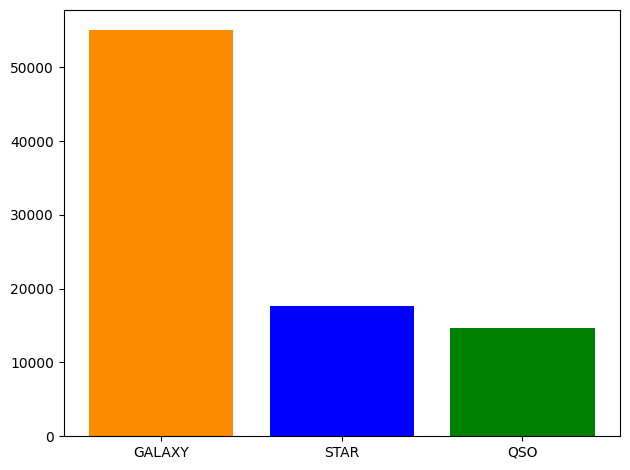

In [11]:
class_diff = df["class"].value_counts(dropna=False)
print(class_diff)

plt.bar(['GALAXY', 'STAR', 'QSO'], [class_diff[0], class_diff[1], class_diff[2]], color=['darkorange', 'blue', 'green'])

plt.tight_layout()
plt.show()

### Чистых объектов стало еще меньше, могут возникнуть проблемы с классификацией квазаров

## 5. Распределение магнитуд по классам в видe гистограммы

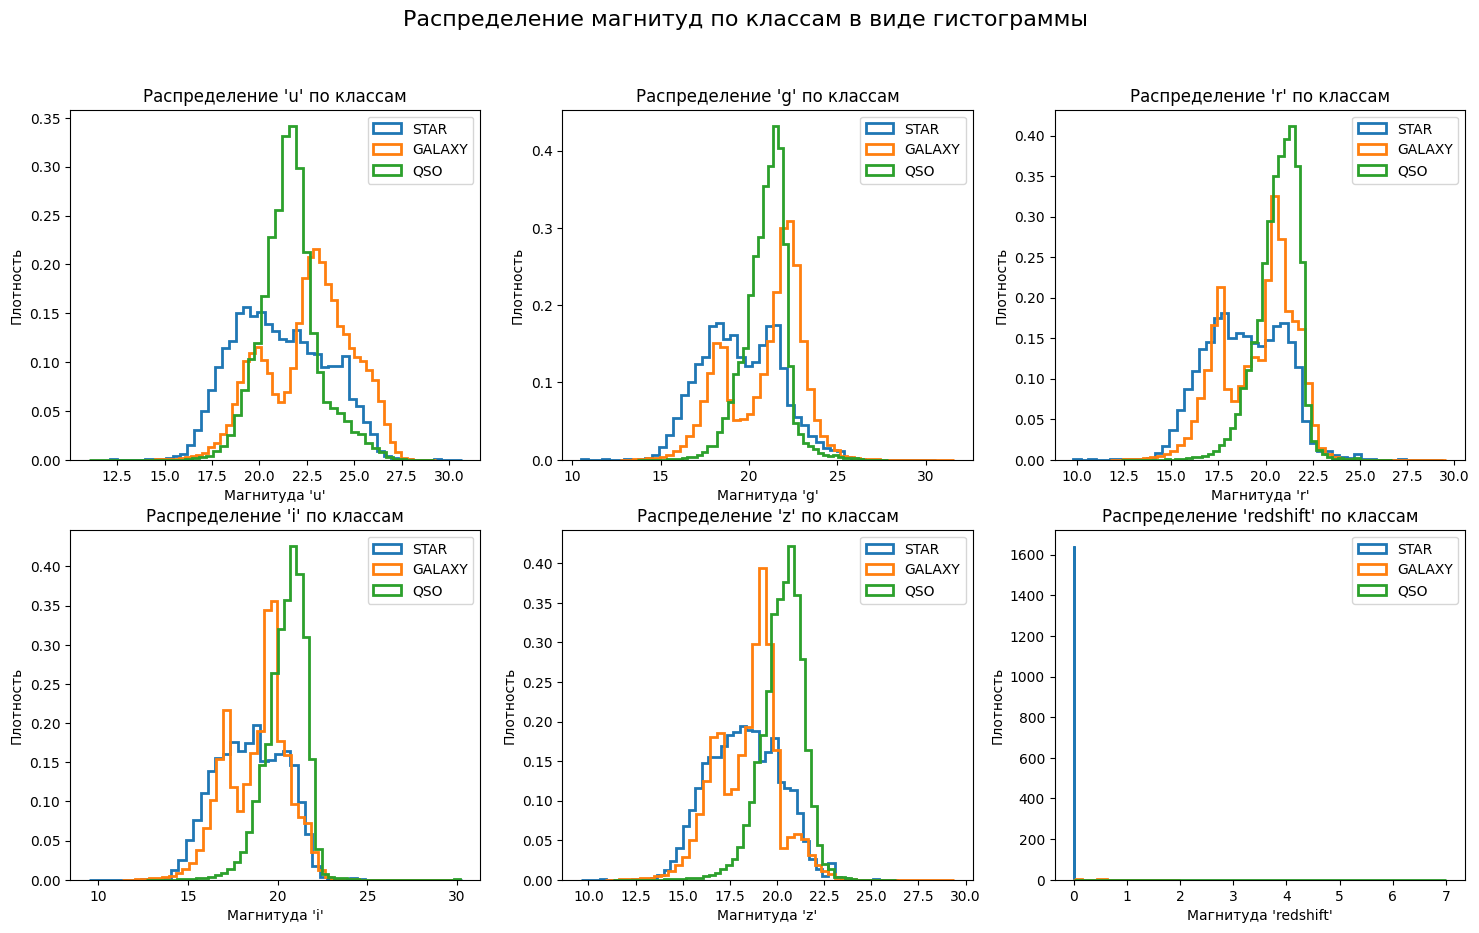

In [12]:
classes = ["STAR", "GALAXY", "QSO"]
magnitudes = ["u", "g", "r", "i", "z", "redshift"]

fig, axes = plt.subplots(2, 3, figsize=(18,10))

for j in range(2):
    for i in range(3):
        if j == 1: k = i + 2
        else: k = i
        for cls in classes:
            x = df.loc[df["class"] == cls, magnitudes[k + j]].dropna()
            axes[j][i].hist(x,bins=50,density=True,histtype='step',linewidth=2,label=cls)

        axes[j][i].set_title(f"Распределение '{magnitudes[k + j]}' по классам")
        axes[j][i].set_xlabel(f"Магнитуда '{magnitudes[k + j]}'")
        axes[j][i].set_ylabel("Плотность")
        axes[j][i].legend()

fig.suptitle(f"Распределение магнитуд по классам в видe гистограммы", fontsize=16)
plt.show() 

### Прослеживаются четкие различия по магнитудам между классами

## 6. Распределение магнитуд по классам в виде ящиков с усами

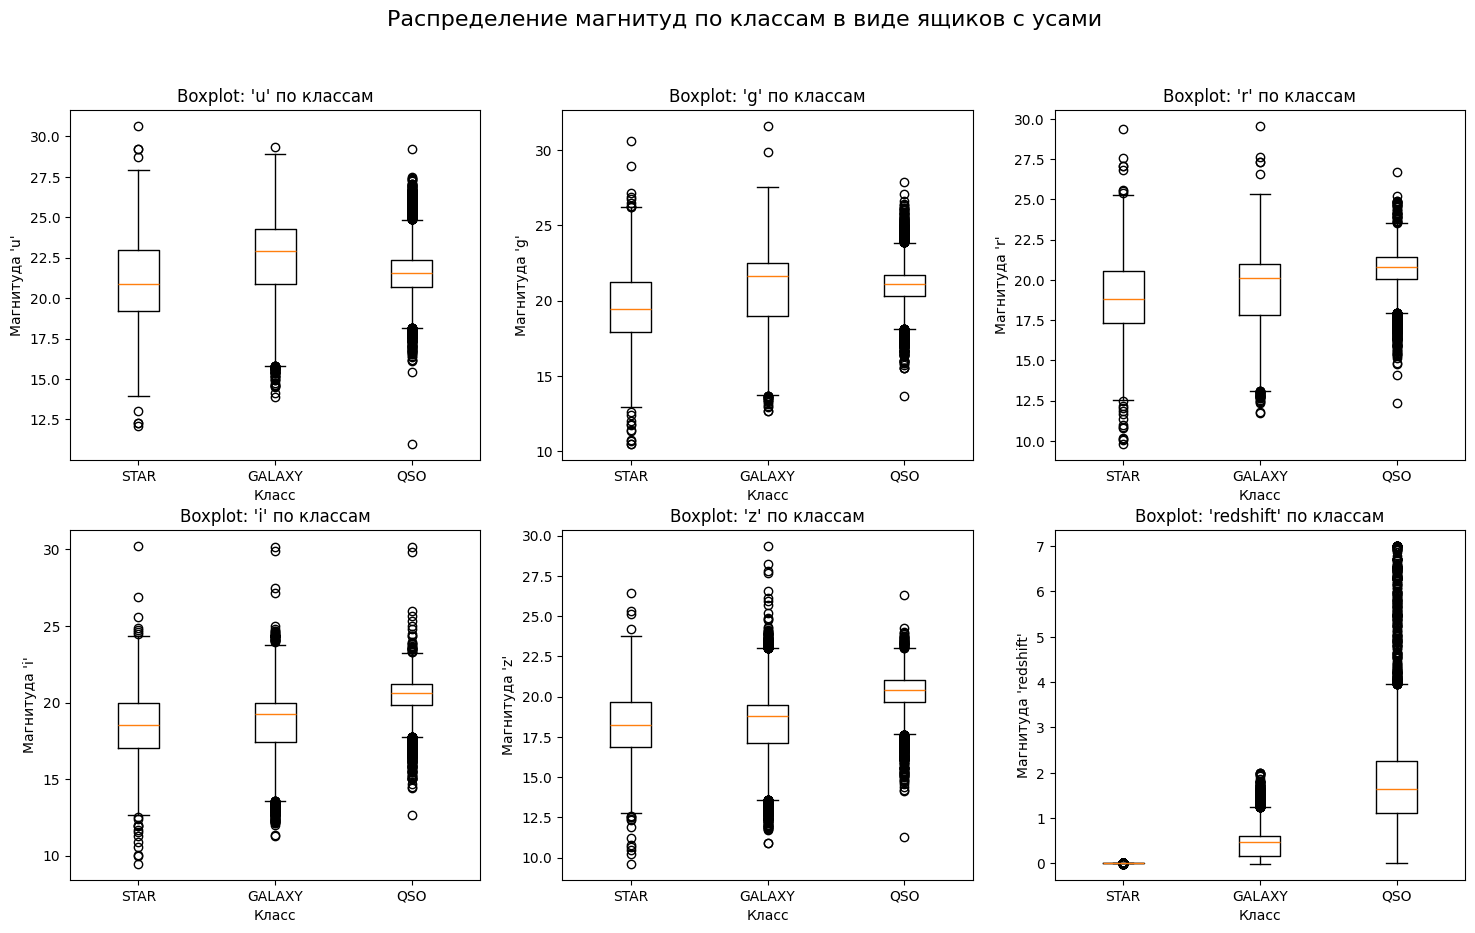

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18,10))

for j in range(2):
    for i in range(3):
        data = []
        labels = []
        if j == 1: k = i + 2
        else: k = i

        for cls in classes:
                x = df.loc[df["class"] == cls, magnitudes[k + j]].dropna()
                data.append(x)
                labels.append(cls)

        axes[j][i].boxplot(data, tick_labels=labels)
        axes[j][i].set_title(f"Boxplot: '{magnitudes[k + j]}' по классам")
        axes[j][i].set_xlabel("Класс")
        axes[j][i].set_ylabel(f"Магнитуда '{magnitudes[k + j]}'")

fig.suptitle(f"Распределение магнитуд по классам в виде ящиков с усами", fontsize=16)
plt.show() 

### (Низачем, просто для красоты, посмотреть на распределение, размах и выбросы, которые сложно считать выбросами)

## 7. Распределение цветов по классам

In [14]:
model_df = df.copy()

print("\nСреднее магнитуд по классам")
display(df.groupby("class")[magnitudes].mean().round(3))

print("\n Медиана магнитуд по классам")
display(df.groupby("class")[magnitudes].median().round(3))


Среднее магнитуд по классам


,u,g,r,i,z,redshift
class,,,,,,
GALAXY,22.629,20.942,19.609,18.863,18.455,0.426
QSO,21.589,20.946,20.643,20.447,20.280,1.740
STAR,21.084,19.544,18.877,18.474,18.267,-0.000



 Медиана магнитуд по классам


,u,g,r,i,z,redshift
class,,,,,,
GALAXY,22.888,21.628,20.134,19.243,18.786,0.463
QSO,21.547,21.089,20.805,20.612,20.391,1.635
STAR,20.889,19.412,18.839,18.506,18.247,-0.000


In [15]:
color_magn = [("u", "g"), ("g", "r"), ("r", "i"), ("i", "z")]
color_col = [f"{a} - {b}" for a, b in color_magn]

for a, b in color_magn:
    model_df[f"{a} - {b}"] = model_df[a] - model_df[b]

print("\nСтатистики цветов:")
model_df[color_col].describe().round(3)


Статистики цветов:


,u - g,g - r,r - i,i - z
count,87221.000,87221.000,87221.000,87221.000
mean,1.482,1.026,0.585,0.327
std,1.190,0.734,0.498,0.422
min,-12.748,-12.319,-13.984,-13.162
25%,0.678,0.424,0.241,0.151
50%,1.365,0.991,0.510,0.346
75%,2.072,1.611,0.917,0.482
max,10.917,14.315,12.206,13.427


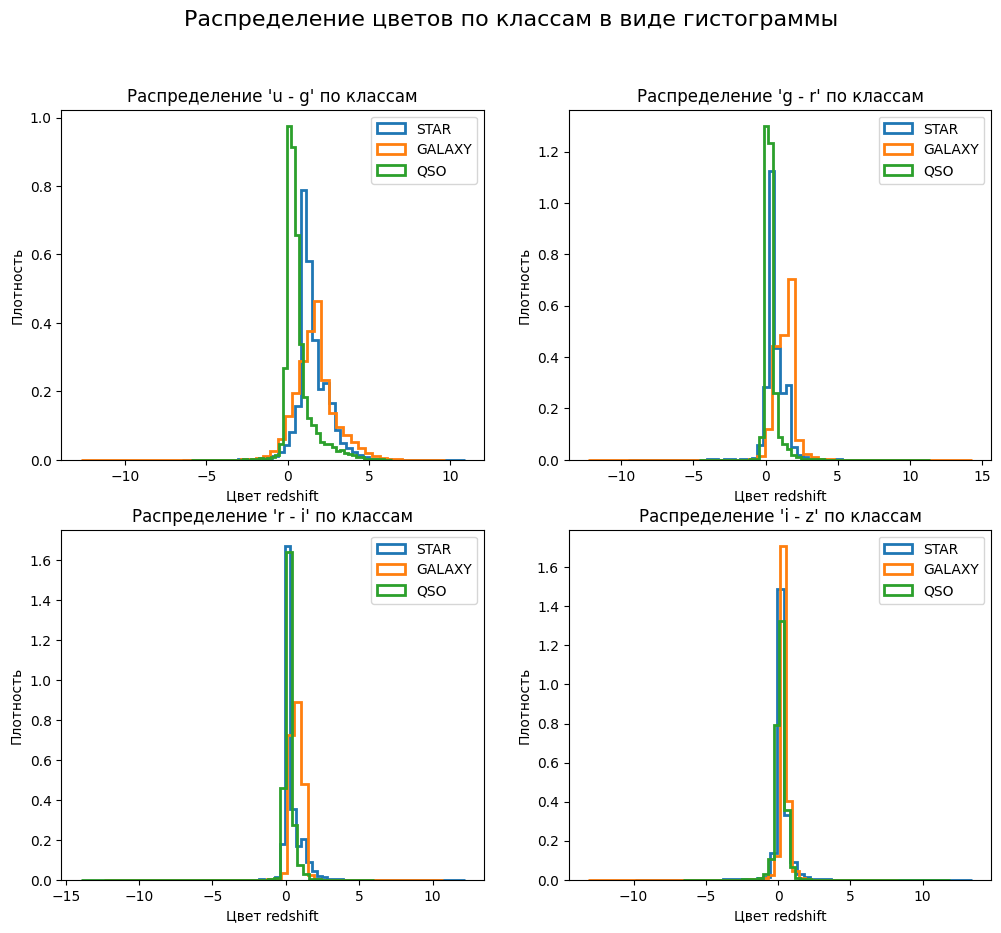

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

for j in range(2):
    for i in range(2):
        if j == 1: k = i + 1
        else: k = i

        for cls in classes:
                x = model_df.loc[model_df["class"] == cls, color_col[k + j]].dropna()
                axes[j][i].hist(x, bins=50, density=True, histtype='step', linewidth=2,label=cls)

        axes[j][i].set_title(f"Распределение '{color_col[k + j]}' по классам")
        axes[j][i].set_xlabel(f"Цвет {col}")
        axes[j][i].set_ylabel("Плотность")
        axes[j][i].legend()

fig.suptitle(f"Распределение цветов по классам в видe гистограммы", fontsize=16)
plt.show() 

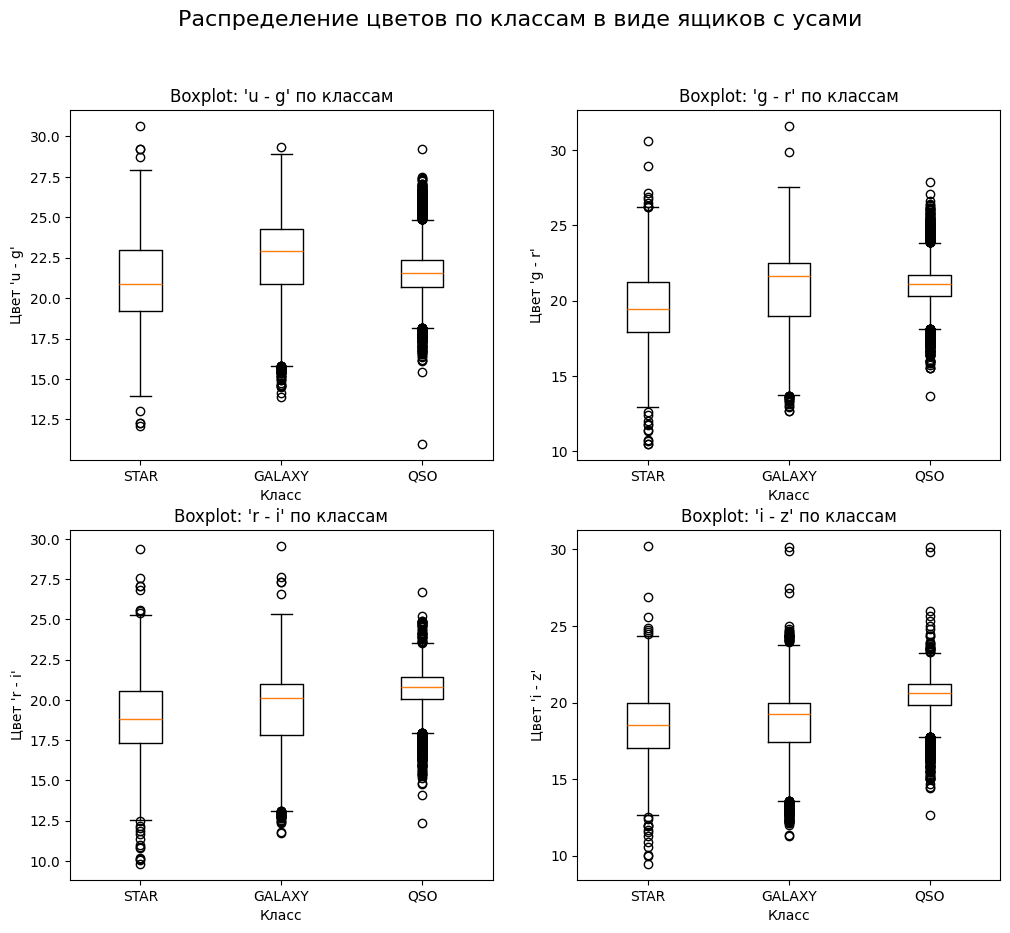

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

for j in range(2):
    for i in range(2):
        data = []
        labels = []
        if j == 1: k = i + 1
        else: k = i

        for cls in classes:
                x = model_df.loc[model_df["class"] == cls, magnitudes[k + j]]
                data.append(x)
                labels.append(cls)

        axes[j][i].boxplot(data, tick_labels=labels)
        axes[j][i].set_title(f"Boxplot: '{color_col[k + j]}' по классам")
        axes[j][i].set_xlabel("Класс")
        axes[j][i].set_ylabel(f"Цвет '{color_col[k + j]}'")

fig.suptitle(f"Распределение цветов по классам в виде ящиков с усами", fontsize=16)
plt.show() 

### Здесь уже размах поменьше, большая концентрация объектов ближе к медиане, все остальное считается выбросами

In [18]:
print("\nСреднее цветов по классам:")
display(model_df.groupby("class")[color_col].mean().round(3))

print("\nМедиана цветов по классам:")
display(model_df.groupby("class")[color_col].median().round(3))


Среднее цветов по классам:


,u - g,g - r,r - i,i - z
class,,,,
GALAXY,1.687,1.333,0.746,0.408
QSO,0.643,0.303,0.196,0.168
STAR,1.540,0.666,0.403,0.207



Медиана цветов по классам:


,u - g,g - r,r - i,i - z
class,,,,
GALAXY,1.646,1.424,0.744,0.394
QSO,0.406,0.213,0.153,0.160
STAR,1.329,0.530,0.212,0.113


## 8. Color-color диаграммы

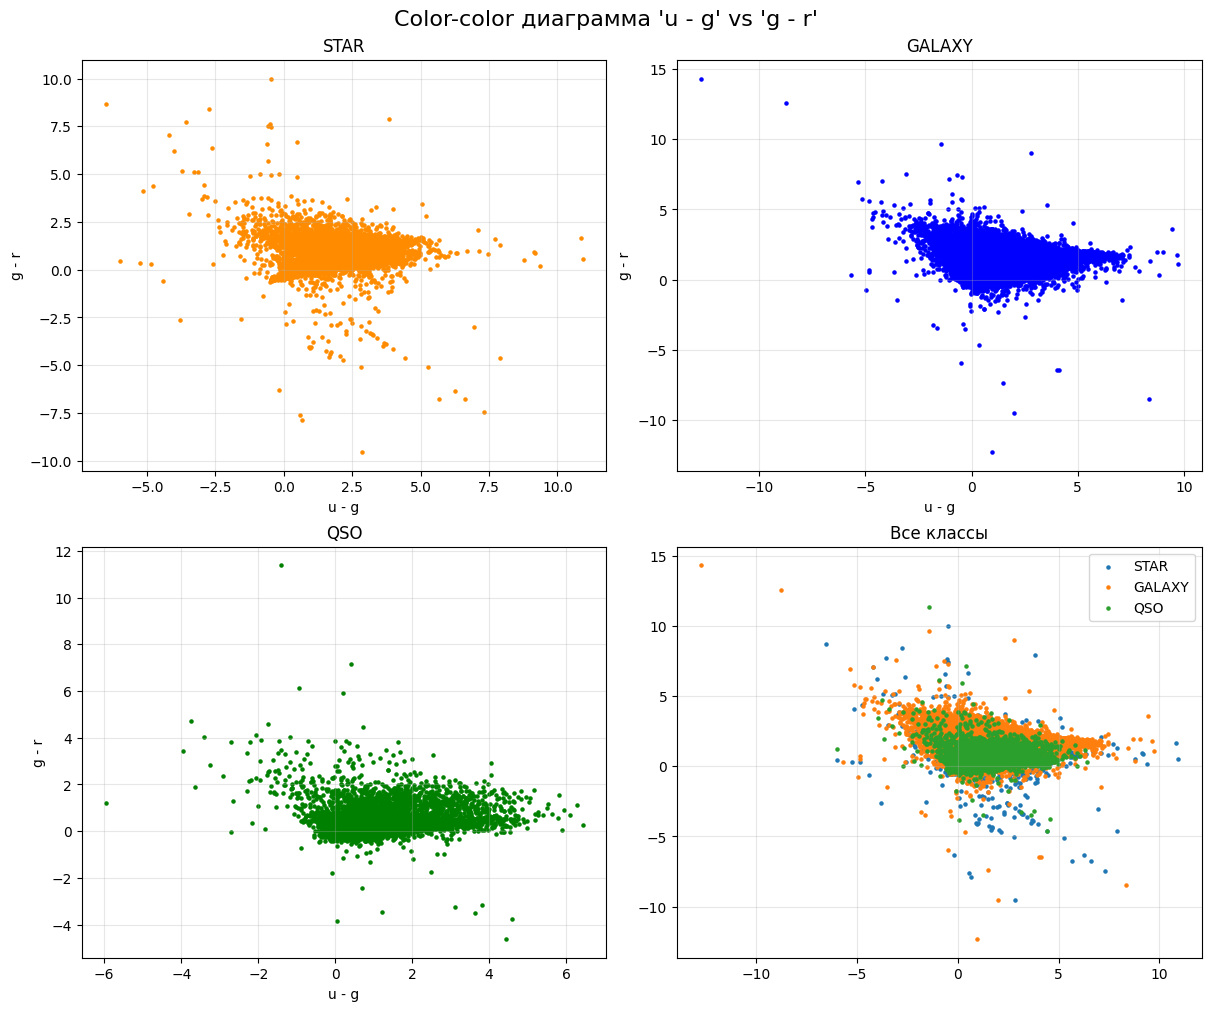

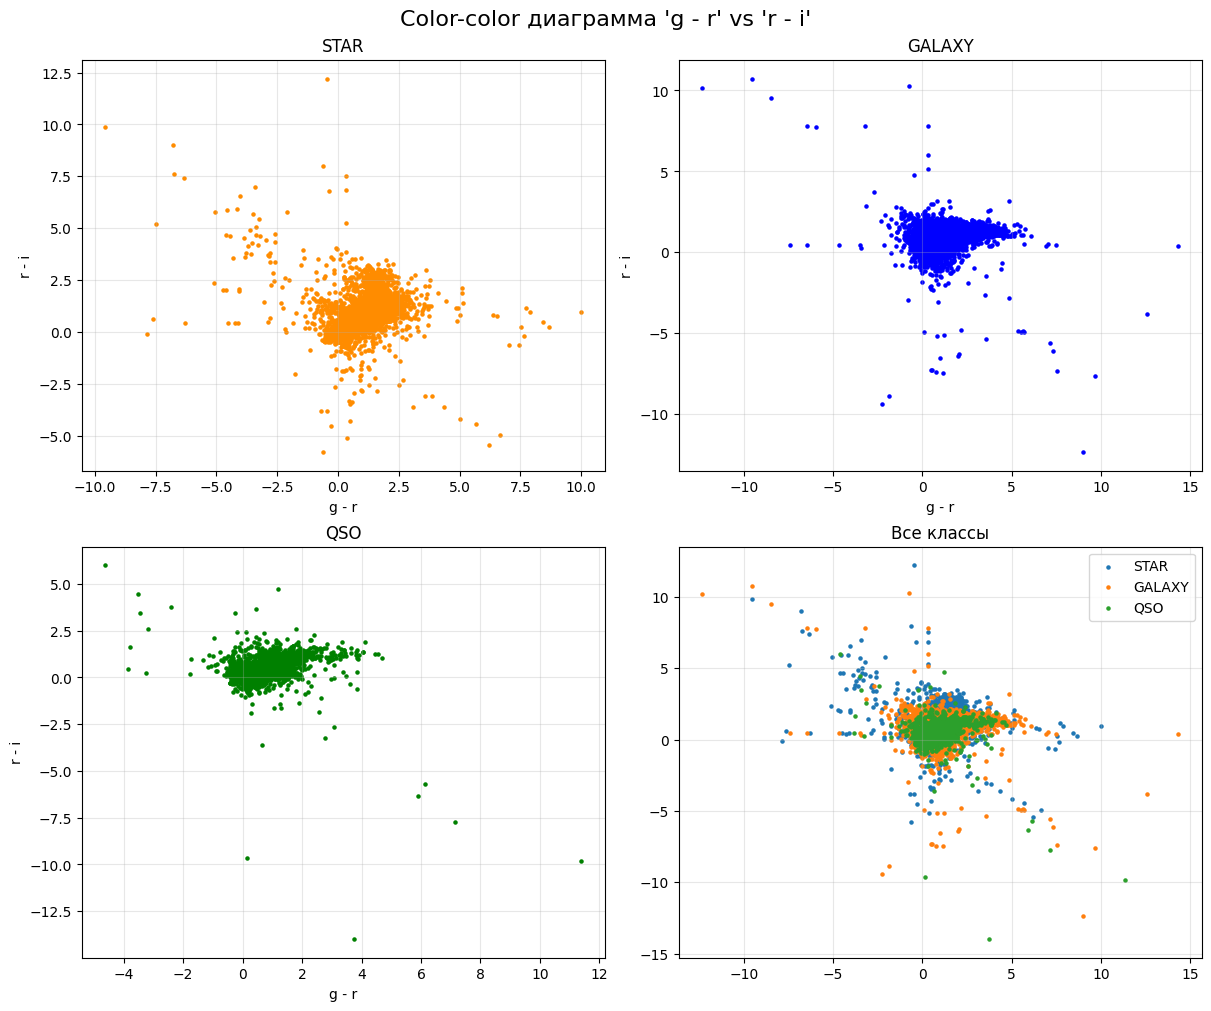

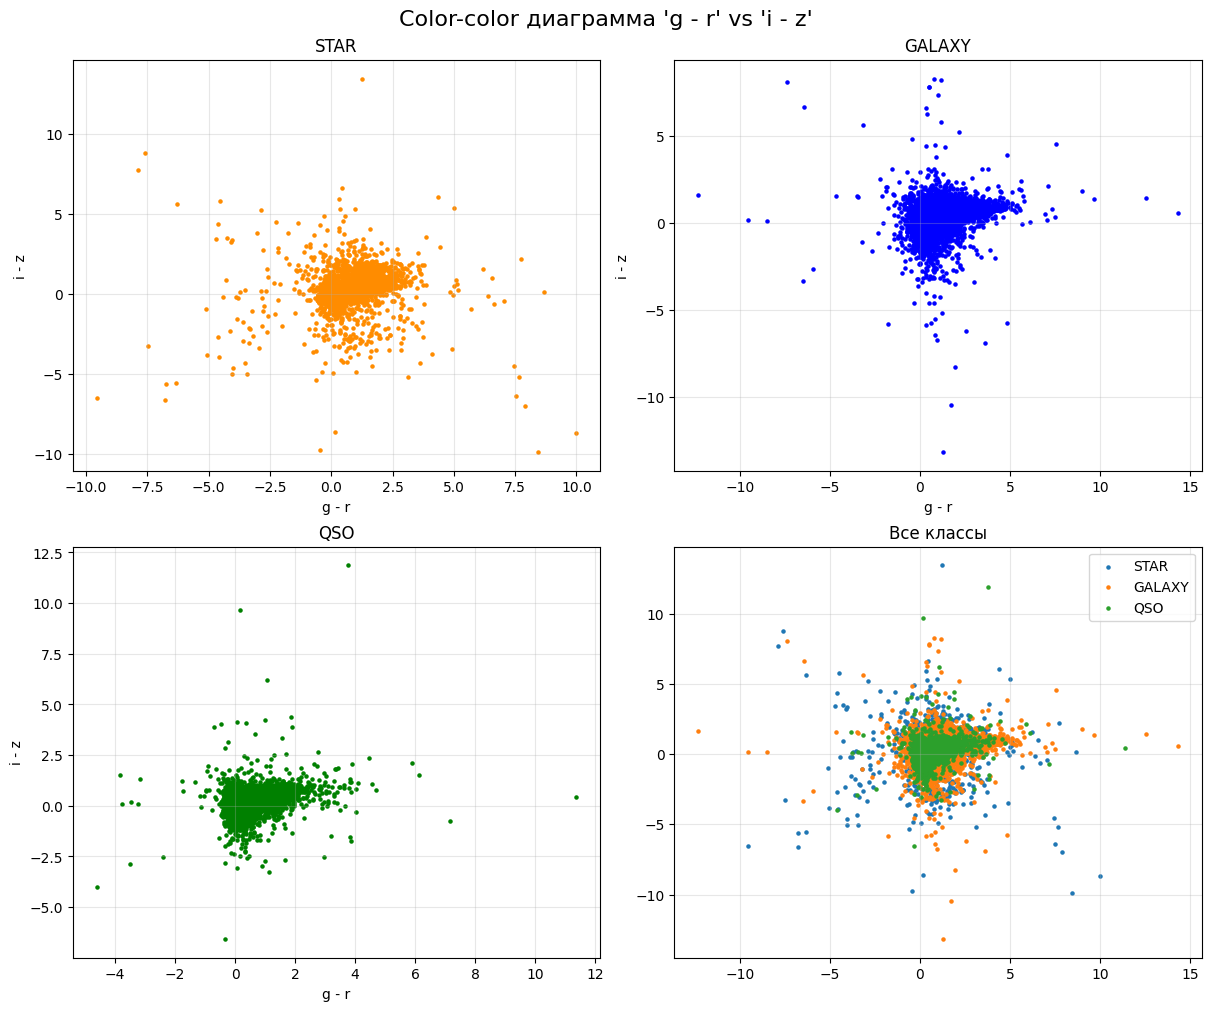

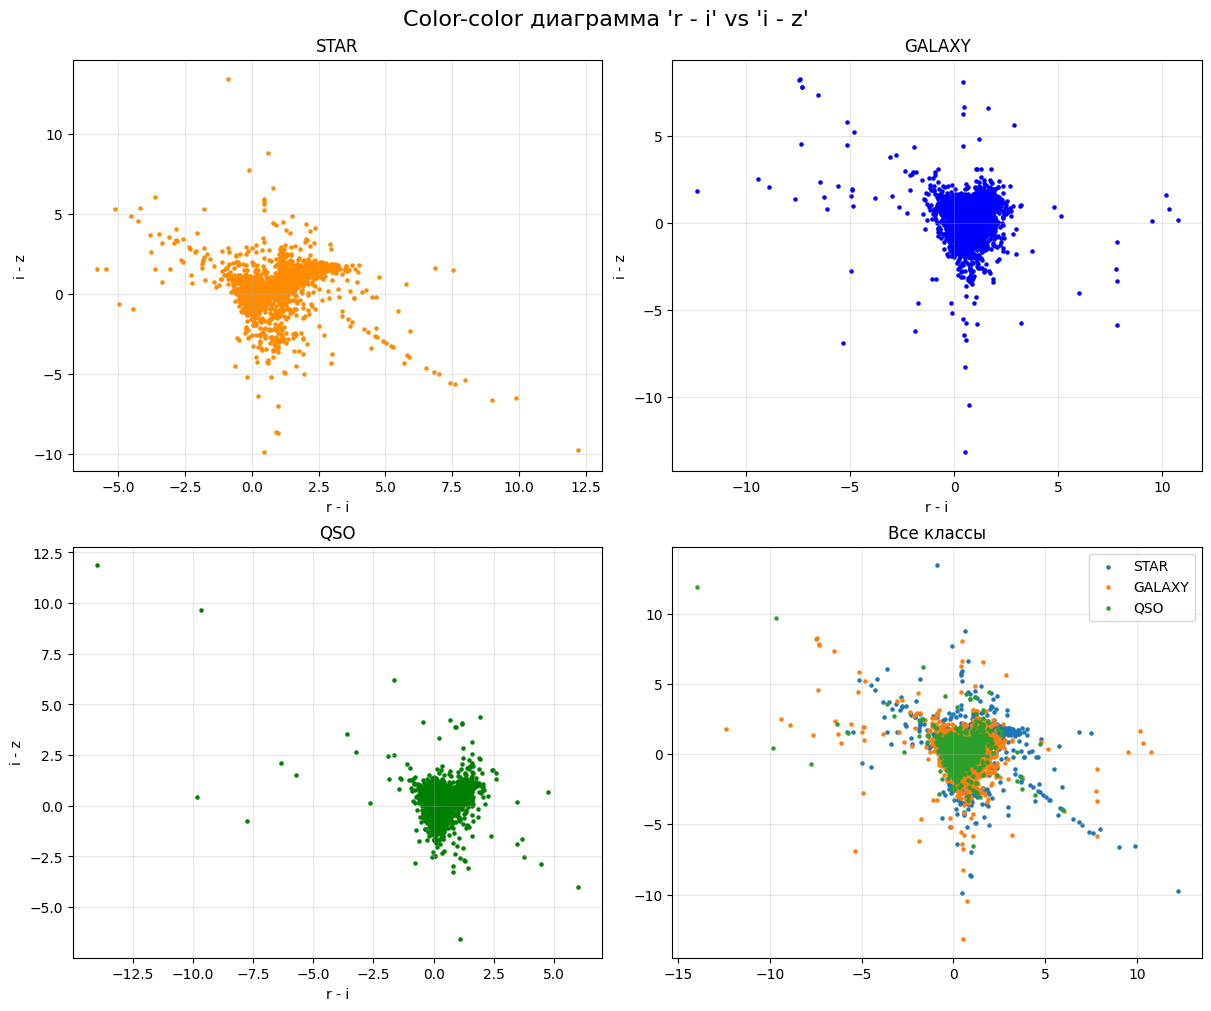

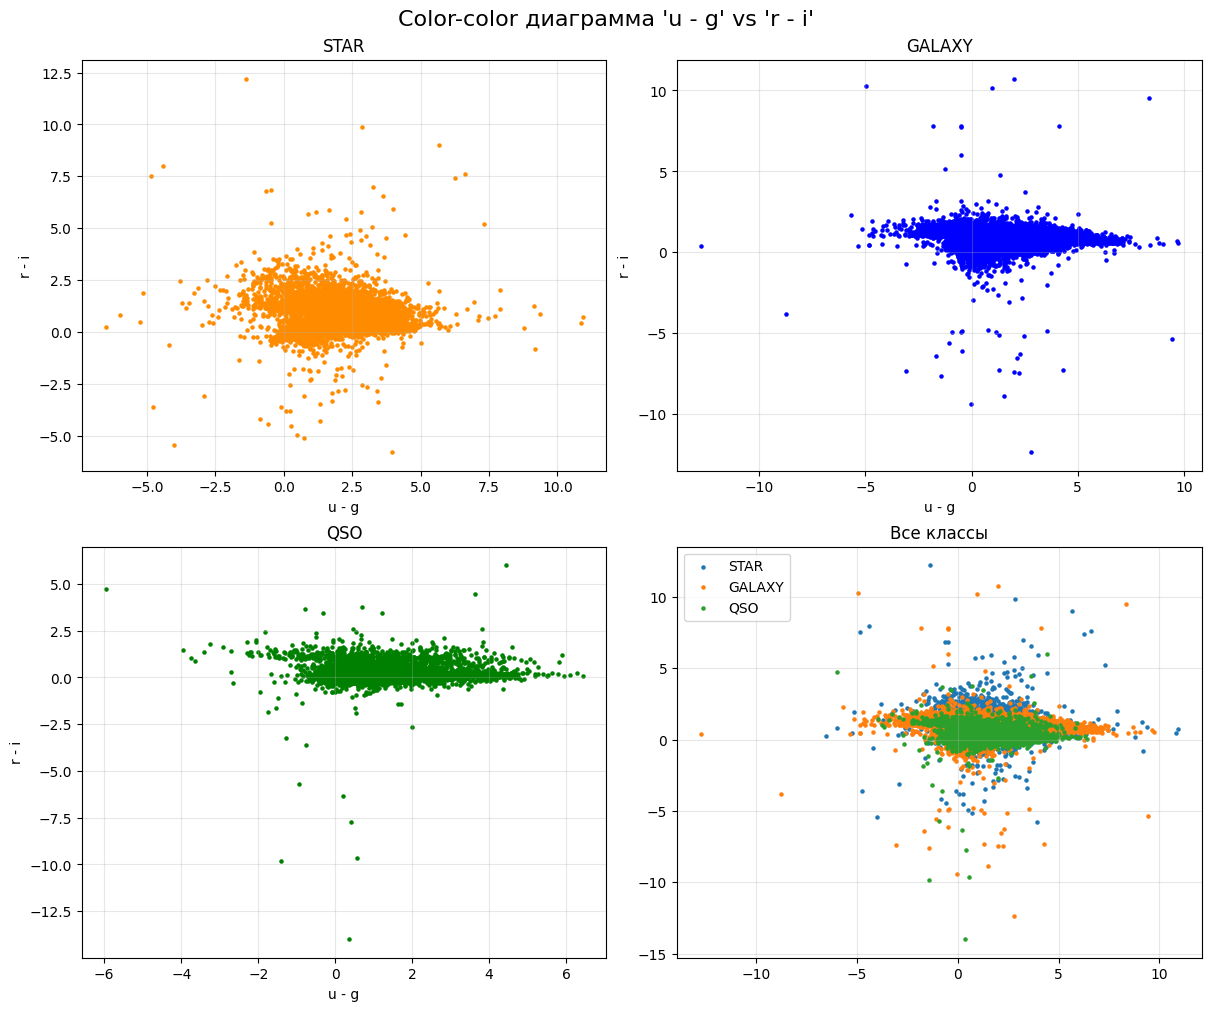

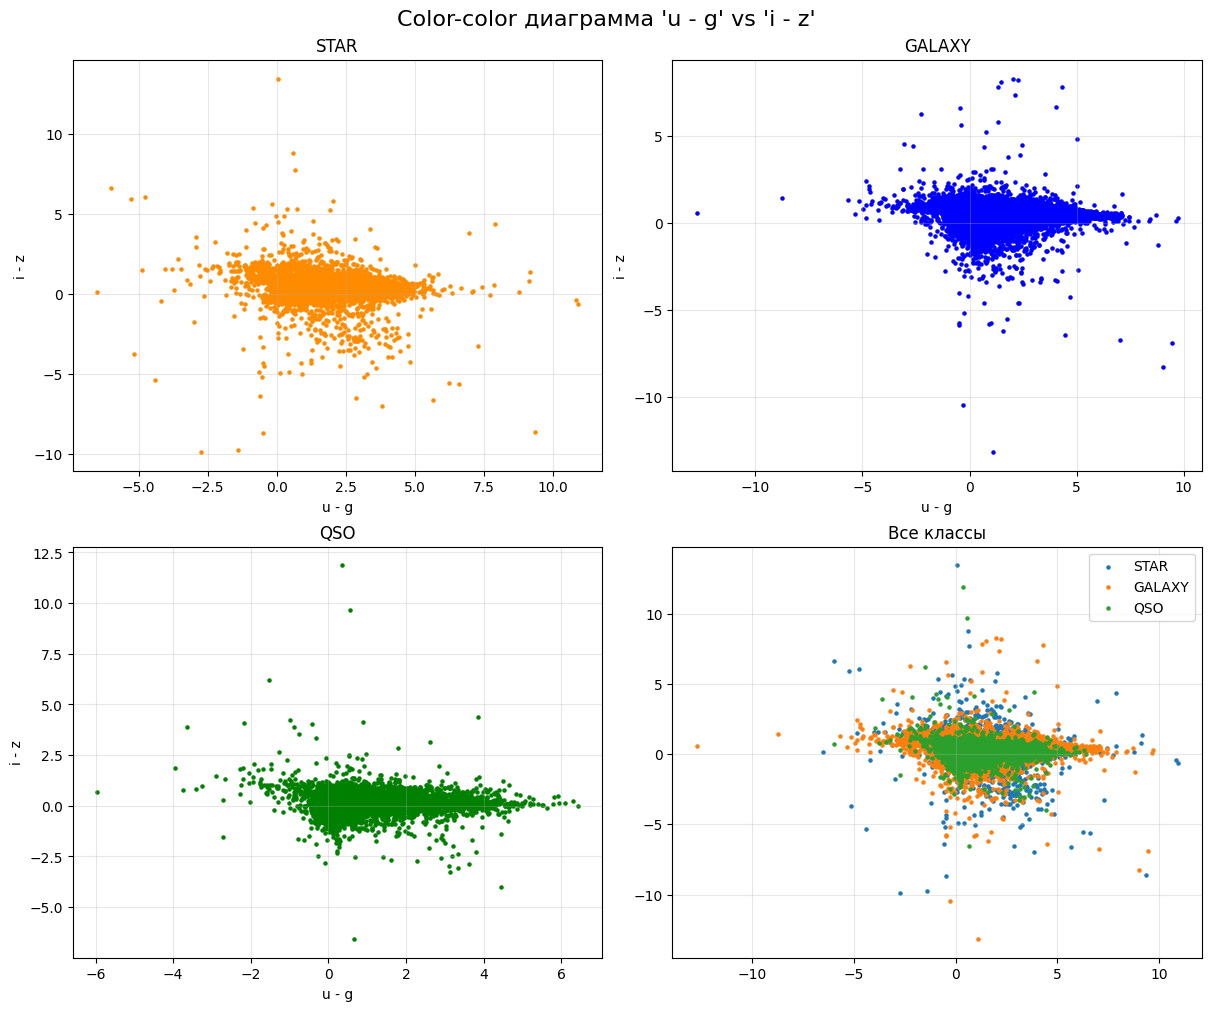

In [19]:
colors_magns = [
    ("u - g", "g - r"),
    ("g - r", "r - i"),
    ("g - r", "i - z"),
    ("r - i", "i - z"),
    ("u - g", "r - i"),
    ("u - g", "i - z")
]
colors = ['darkorange', 'blue', 'green']

for x, y in colors_magns:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
    axes = axes.ravel()

    for i, cls in enumerate(classes):
        sub = model_df[model_df["class"] == cls]
        axes[i].scatter(sub[x], sub[y], s=5, alpha=1, color=colors[i])
        axes[i].set_title(cls)
        axes[i].set_xlabel(x)
        axes[i].set_ylabel(y)
        axes[i].grid(alpha=0.3)

    for cls in classes:
        sub = model_df[model_df["class"] == cls]
        axes[3].scatter(sub[x], sub[y], s=5, alpha=1, label=cls)
        axes[3].set_title("Все классы")
        axes[3].grid(alpha=0.3)
        axes[3].legend()

    fig.suptitle(f"Color-color диаграмма '{x}' vs '{y}'", fontsize=16)
    plt.show()

### У каждого цвета прослеживаются свои паттерны, которые уже моделька и будет отыскивать и классифицировать. У всех цветов большая концентрация объектов любых классов в центре.

## 9. Корреляционный анализ

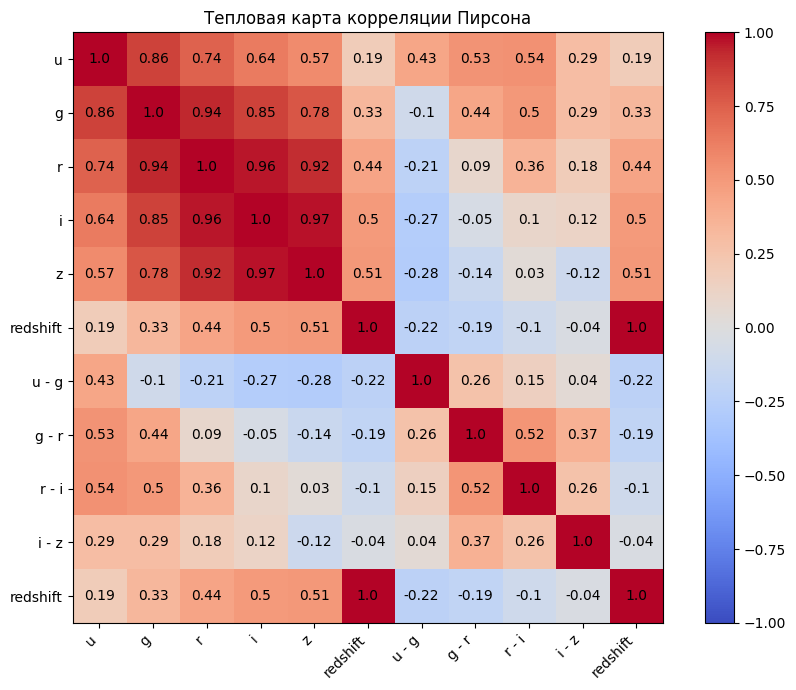

In [20]:
corr_cols = magnitudes + color_col + ["redshift"]
corr = model_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{round(corr.iloc[i, j], 2)}", ha="center", va="center")

plt.colorbar(heatmap, ax=ax)
ax.set_title("Тепловая карта корреляции Пирсона")

plt.tight_layout()
plt.show()

### Магнитуды между собой имеют сильную корреляцию, за исключением магнитуды *u*. Обычные магнитуды как набор признаков избыточны, набор цветов в этом случае лучше будет работать для обучения модели.

## 10. Карта неба по классам

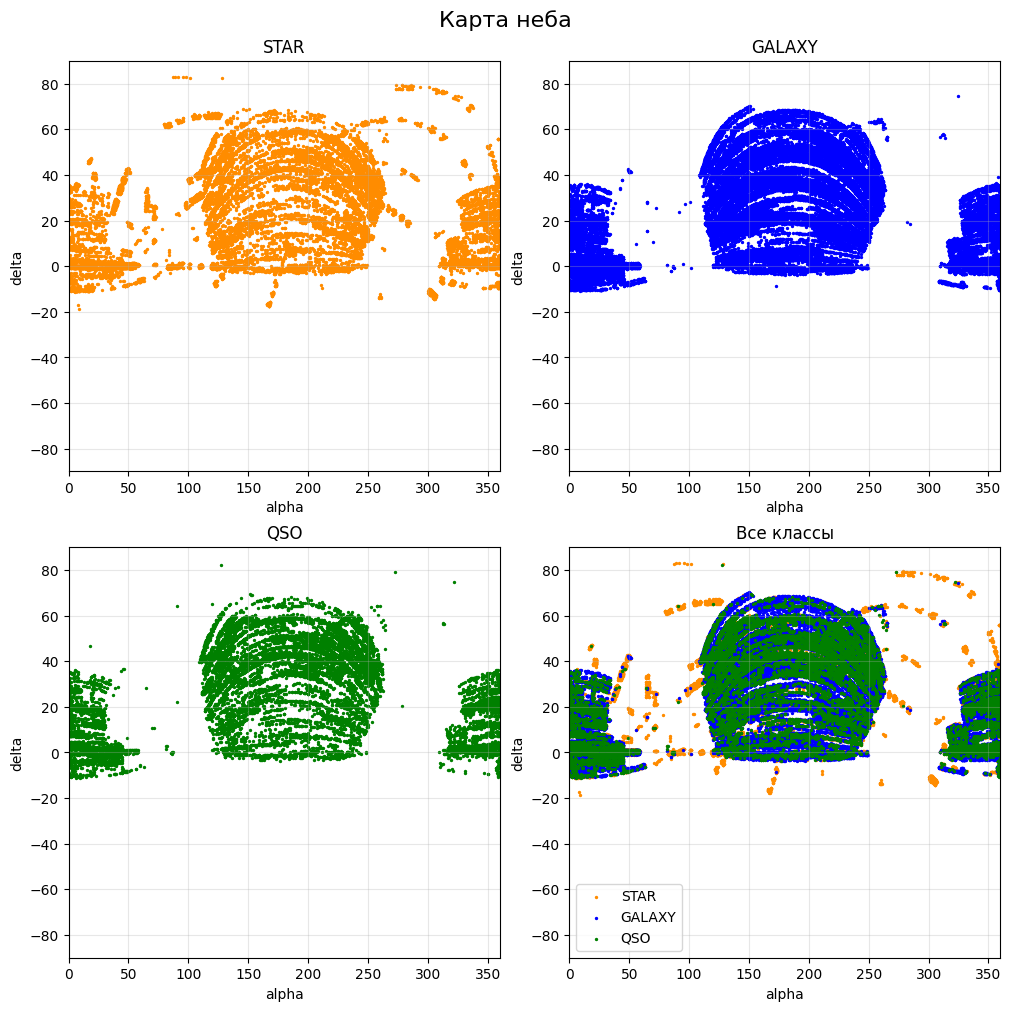

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
axes = axes.ravel()

# Три отдельных класса
for i, cls in enumerate(classes):
    sub = model_df[model_df["class"] == cls]
    axes[i].scatter(sub["alpha"], sub["delta"], s=2, alpha=1, color=colors[i])
    axes[i].set_title(cls)
    axes[i].set_xlabel("alpha")
    axes[i].set_ylabel("delta")
    axes[i].set_xlim(0, 360)
    axes[i].set_ylim(-90, 90)
    axes[i].grid(alpha=0.3)

# Все классы вместе
for i, cls in enumerate(classes):
    sub = model_df[model_df["class"] == cls]
    axes[3].scatter(sub["alpha"], sub["delta"], s=2, alpha=1,color=colors[i], label=cls)
    axes[3].set_title("Все классы")
    axes[3].set_xlabel("alpha")
    axes[3].set_ylabel("delta")
    axes[3].set_xlim(0, 360)
    axes[3].set_ylim(-90, 90)
    axes[3].grid(alpha=0.3)
    axes[3].legend()

fig.suptitle("Карта неба", fontsize=16)
plt.show()

### Из карты прослеживается принцип съемки неба и сбора данных, классы не зависят от координат и не будут мешать обучению. Можно выделить два основных класса, на которые поделены объекты. Классы имеют идентичный рисунок на карте неба.

# Обучение моделей

### Для решения задачи классификации небесных тел возьмем основные три модели логистическую регрессию, случайный лес и метод опорных веторов

#### В качестве метода кросс-валидации для обучения модели взята схема **StratifiedGroupKFold**, так как она сохраняет баланс классов в каждом фолде и неразрывность групп.

In [22]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

homework_random_state = 42

## Обучение моделей

In [23]:
le = LabelEncoder()
le.fit(["GALAXY", "STAR", "QSO"])
y = le.transform(model_df["class"])
X = model_df[["u", "g", "r", "i", "z", "u - g", "g - r", "r - i", "i - z"]].values

In [24]:
groups = model_df["obj_ID"].values

cross_val = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=homework_random_state)

train_idx, test_idx = next(cross_val.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

assert len(set(groups_train) & set(groups_test)) == 0, "Утечка: obj_ID в train и test"

print(f"Размерность тренировочных данных: {X_train.shape}")
print(f"Размерность тестовых данных: {X_test.shape}")
print(f"\nБаланс классов тренировочных данных: {np.bincount(y_train)}")
print(f"Баланс test:  {np.bincount(y_test)}")

Размерность тренировочных данных: (69776, 9)
Размерность тестовых данных: (17445, 9)

Баланс классов тренировочных данных: [44004 11687 14085]
Баланс test:  [11001  2922  3522]


In [25]:
logistic_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000,random_state=homework_random_state))
svc_pipe = make_pipeline(StandardScaler(),LinearSVC(max_iter=5000, random_state=homework_random_state))
rf_pipe = make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=homework_random_state, n_jobs=-1))

logistic_pipe.fit(X_train, y_train)
svc_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are compu

## Запуск моделей на тестовой выборке

In [26]:
y_log_pred = logistic_pipe.predict(X_test)
y_svc_pred = svc_pipe.predict(X_test)
y_rf_pred = rf_pipe.predict(X_test)

acc_lin = accuracy_score(y_test, y_log_pred)
acc_svc = accuracy_score(y_test, y_svc_pred)
acc_rand_forest = accuracy_score(y_test, y_rf_pred)

f1_lin = f1_score(y_test, y_log_pred, average="macro")
f1_svc = f1_score(y_test, y_svc_pred, average="macro")
f1_rf = f1_score(y_test, y_rf_pred, average="macro")

print("Accuracy:")
print(f"Логистическая регрессия {acc_lin:.4f}")
print(f"Метод опорных векторов {acc_svc:.4f}")
print(f"Случайный лес {acc_rand_forest:.4f}")

print("\nF1:")
print(f"Логистическая регрессия {f1_lin:.4f}")
print(f"Метод опорных векторов {f1_svc:.4f}")
print(f"Случайный лес {f1_rf:.4f}")

Accuracy:
Логистическая регрессия 0.7707
Метод опорных векторов 0.7507
Случайный лес 0.8931

F1:
Логистическая регрессия 0.6671
Метод опорных векторов 0.5917
Случайный лес 0.8546


### Результаты тестов

| Модель | Метрика | Значение | Метрика | Значение |
|---|---|---|---|---|
| Логистическая регрессия | Accuracy | 0.7707 | F1 | 0.6671 |
| Метод опорных векторов | Accuracy | 0.7507 | F1 | 0.5917 |
| Случайный лес | Accuracy | 0.8931 | F1 | 0.8546 |

#### Лучшие результаты показала модель **RandomForestClassifier**, хуже всех справилась **LinearSVC**. В целом, достаточно хорошие результаты по итогам одной прогонки, но можно и дообучить модель


## Матрица ошибок

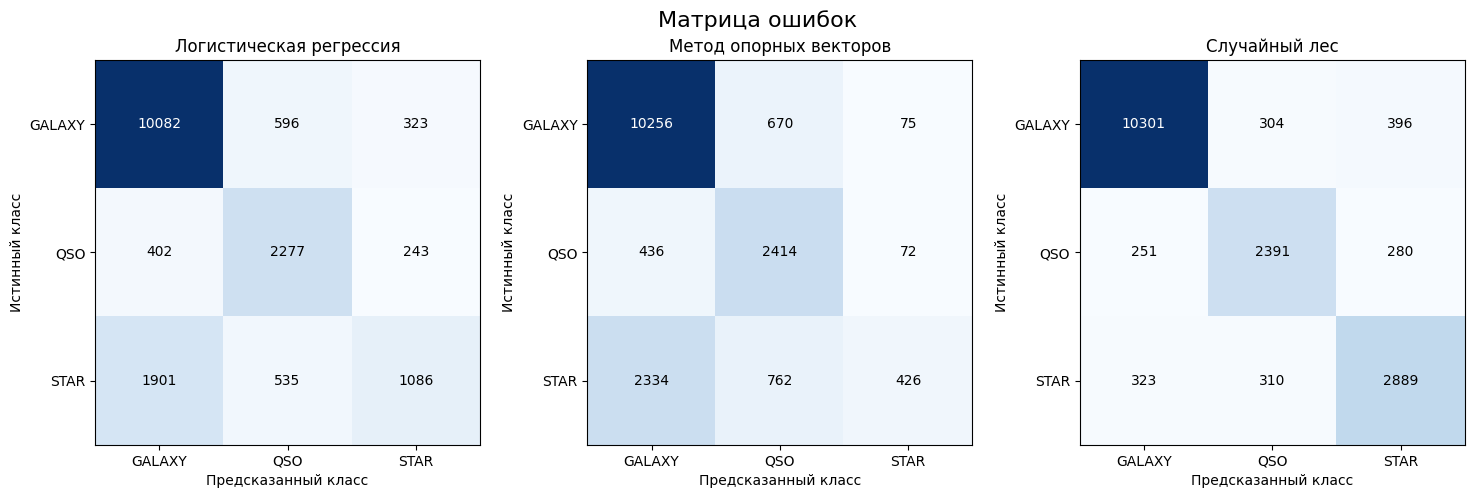

In [27]:
cm_log = confusion_matrix(y_test, y_log_pred, labels=[0, 1, 2])
cm_svc = confusion_matrix(y_test, y_svc_pred, labels=[0, 1, 2])
cm_rf = confusion_matrix(y_test, y_rf_pred, labels=[0, 1, 2])
names = ["Логистическая регрессия", "Метод опорных векторов", "Случайный лес"]
models_cm = [cm_log, cm_svc, cm_rf]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i in range(3):
    axes[i].imshow(models_cm[i], cmap="Blues")
    axes[i].set_xticks([0, 1, 2], le.classes_)
    axes[i].set_yticks([0, 1, 2], le.classes_)
    axes[i].set_xlabel("Предсказанный класс")
    axes[i].set_ylabel("Истинный класс")
    axes[i].set_title(names[i])
    for k in range(3):
        for j in range(3):
            axes[i].text(j, k, str(models_cm[i][k, j]), ha="center", va="center",
                    color="white" if models_cm[i][k, j] > models_cm[i].max() / 2 else "black")

fig.suptitle("Матрица ошибок", fontsize=16)
plt.show()

In [28]:
#print(svc_pipe.named_steps)

## График важностей признаков на этапе обучения

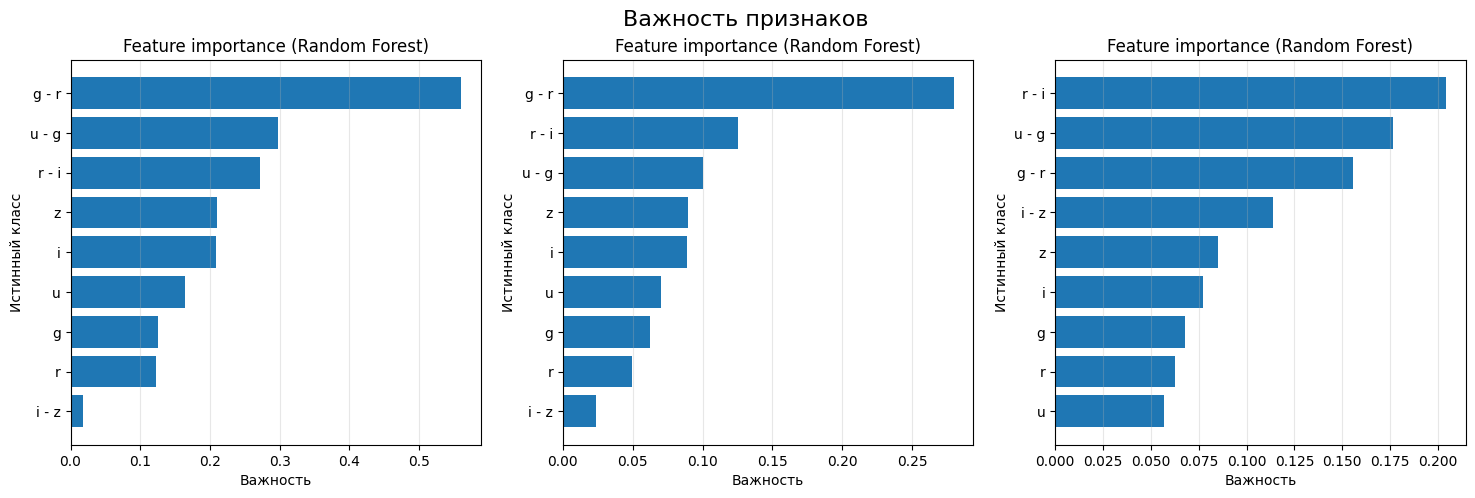

In [29]:
imp_log = pd.DataFrame({
    "feature": ["u", "g", "r", "i", "z", "u - g", "g - r", "r - i", "i - z"],
    "importance": np.abs(logistic_pipe.named_steps["logisticregression"].coef_).mean(axis=0),
}).sort_values("importance", ascending=True)

imp_svc = pd.DataFrame({
    "feature": ["u", "g", "r", "i", "z", "u - g", "g - r", "r - i", "i - z"],
    "importance": np.abs(svc_pipe.named_steps["linearsvc"].coef_).mean(axis=0),
}).sort_values("importance", ascending=True)

imp_rf = pd.DataFrame({
    "feature": ["u", "g", "r", "i", "z", "u - g", "g - r", "r - i", "i - z"],
    "importance": rf_pipe.named_steps["randomforestclassifier"].feature_importances_,
}).sort_values("importance", ascending=True)

imp = [imp_log, imp_svc, imp_rf]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i in range(3):
    axes[i].barh(imp[i]["feature"], imp[i]["importance"])
    axes[i].set_xlabel("Важность")
    axes[i].set_ylabel("Истинный класс")
    axes[i].set_title("Feature importance (Random Forest)")
    axes[i].grid(alpha=0.3, axis="x")


fig.suptitle("Важность признаков", fontsize=16)
plt.show()


## Вывод по работе

### **Выводы по EDA**
- Из 100000 строк удалено 12779 (12.8%) из-за конфликтующих obj_ID и 1 строка с невалидными значениями.
GALAXY    55005
STAR      17607
QSO       14609
- Баланс классов. GALAXY 55005 / STAR 17607 / QSO 14609 - сильный перекос в пользу галактик, квазаров мало. Это определяет выбор метрик.
- Что показали графики:
    - Гистограммы/boxplot магнитуд - у классов унакальное распределение, но сосредоточены они примерно в одном месте, медианы сравнитиельно близки
    - Color-color диаграммы - У каждого класса свой уникальный паттерн. Сигнал живёт в цветах, а не в яркостях.
    - Корреляционная тепловая карта - соседние магнитуды избыточны
- Карта неба - классы перемешаны по всем регионам.

### **Выводы по обучению**

#### Обоснование выбора моделей:
##### *LogisticRegression*

| Преимущества | Недостатки |
| --- | --- |
| Быстро обучается | Чувствительность к мультиколлинеарности |
| Нет строгих предположений о распределении классов | Неустойчивость к выбросам |
| Устойчива к переобучению | Смещение при дисбалансе классов |

##### *LinearSVC*

| Преимущества | Недостатки |
| --- | --- |
| Высокая скорость работы на больших наборах данных | Сложность интерпретации модели |
| Эффективность в пространствах высокой размерности | Неустойчивость к выбросам |
| Устойчива к переобучению | Ограниченность линейными границами |

##### *RandomForestClassifier*

| Преимущества | Недостатки |
| --- | --- |
| Устойчивость к выбросам | Требовательность к вычислительным ресурсам |
| Устойчивость к дисбалансу | Склонность к переобучению на зашумлённых данных |
| Устойчива к переобучению | Большой размер модели |

#### Обоснование выбора метрики:

##### *Accuracy*

| Преимущества | Недостатки |
| --- | --- |
| Простота и понятность | Не учитывает дисбаланс классов |
| Используется как базовый ориентир | Ограниченность при мультиклассовой классификации |

##### *macro-F1*

| Преимущества | Недостатки |
| --- | --- |
| Сбалансированная оценка при дисбалансе классов | Сложность интерпретации в многоклассовых задачах |
| Жёсткий тест на редкие классы | Чувствительность к низкой производительности на малочисленных классах |

## Пример работы модели

In [30]:
import joblib
from pathlib import Path

MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(rf_pipe, MODEL_DIR / "rf_pipe.joblib")
joblib.dump(logistic_pipe, MODEL_DIR / "linear_pipe.joblib")
joblib.dump(svc_pipe, MODEL_DIR / "svm_pipe.joblib")
joblib.dump(le, MODEL_DIR / "label_encoder.joblib")


['models\\label_encoder.joblib']

In [31]:
# import joblib
# import numpy as np
# import pandas as pd
# from pathlib import Path

MODEL_DIR = Path("models")

rf_pipe = joblib.load(MODEL_DIR / "rf_pipe.joblib")
le = joblib.load(MODEL_DIR / "label_encoder.joblib")

In [32]:
new_data = pd.DataFrame({
    "u": [22.629, 21.084, 21.589],
    "g": [20.942, 19.544, 20.946],
    "r": [19.609, 18.877, 20.643],
    "i": [18.863, 18.474, 20.447],
    "z": [18.455, 18.267, 20.280],
}, index=["объект_1", "объект_2", "объект_3"])

for a, b in [("u","g"), ("g","r"), ("r","i"), ("i","z")]:
    new_data[f"{a} - {b}"] = new_data[a] - new_data[b]

features = ["u", "g", "r", "i", "z", "u - g", "g - r", "r - i", "i - z"]
X_new = new_data[features].values

pred_num = rf_pipe.predict(X_new)
pred_class = le.inverse_transform(pred_num)

proba = rf_pipe.predict_proba(X_new)

result = new_data[features].copy()
result["предсказанный класс"] = pred_class
result["вероятность класса"] = proba[np.arange(len(proba)), pred_num].round(3)

result.head()

,u,g,r,i,z,u - g,g - r,r - i,i - z,предсказанный класс,вероятность класса
объект_1,22.629,20.942,19.609,18.863,18.455,1.687,1.333,0.746,0.408,GALAXY,0.595
объект_2,21.084,19.544,18.877,18.474,18.267,1.540,0.667,0.403,0.207,GALAXY,0.565
объект_3,21.589,20.946,20.643,20.447,20.280,0.643,0.303,0.196,0.167,QSO,0.740


Ссылка на Коллаб https://colab.research.google.com/drive/1on4umm8H6yP97kWHUO1-Xs4CNm3G7VyU?usp=sharing